# Denoising the covariance matrix

Based on my notes from López de Prado, *Machine Learning for Asset Managers*, ch. 2

This is a form of principal component analysis specifically applied in the book to financial market data

## Problem
Covariance matrices are estimated from a limited number of observations relative to the
number of parameters (21 ETFs → 231 parameters from 504 days). Part of what is estimated
is noise. Even when the matrix is invertible, small eigenvalues make it ill-conditioned:
inverting it, as optimisers do, amplifies estimation erros

**Consequence:** unstable weights, misallocation to assets whose apparent diversification
is a sampling artefact, and higher turnover and transaction costs

## Method
### Selected: Constant residual eigenvalue
The Marčenko–Pastur distribution gives the range of eigenvalues expected from pure noise,
given q = observations / assets. Eigenvalues above its upper bound are signal; those below
are treated as noise. Denoising replaces the noise eigenvalues with their average and
rebuilds the correlation matrix, removing noise while keeping the signal eigenvalues
unchanged

**Consequence:** Raising the smallest eigenvalues lowers the condition number (largest / smallest
eigenvalue), so the matrix is better conditioned and the optimiser is more stable.

### Standard correlation matrix

In [241]:
# Imports

import pandas as pd
import numpy as np
from matplotlib.ticker import LogLocator, StrMethodFormatter, NullLocator
import matplotlib.pyplot as plt
from vportfolio.params import LOOKBACK
from vportfolio import load_data, engine

In [242]:
# data

data = load_data.load_universe()
print(data.keys())

dict_keys(['close', 'open', 'returns', 'eligible', 'rebal_dates', 'cost_bp', 'rf_daily'])


In [243]:
# we need to pick one date from which we caluclate the lookback window

# let's take the last date of the research period
decision_date = data["rebal_dates"].iloc[-1]
print(decision_date)

2021-12-31 00:00:00


In [244]:
# calculate the lookback window
window = engine.lookback_window(data["returns"], data["eligible"], decision_date, n=LOOKBACK)
# check the result of the lookback window selection
print(window.shape)
print(window.info())

(504, 21)
<class 'pandas.DataFrame'>
DatetimeIndex: 504 entries, 2020-01-03 to 2021-12-31
Data columns (total 21 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SPY     504 non-null    float64
 1   QQQ     504 non-null    float64
 2   IWM     504 non-null    float64
 3   EFA     504 non-null    float64
 4   EEM     504 non-null    float64
 5   TLT     504 non-null    float64
 6   IEF     504 non-null    float64
 7   SHY     504 non-null    float64
 8   TIP     504 non-null    float64
 9   LQD     504 non-null    float64
 10  HYG     504 non-null    float64
 11  EMB     504 non-null    float64
 12  EMLC    504 non-null    float64
 13  GLD     504 non-null    float64
 14  DBC     504 non-null    float64
 15  XLE     504 non-null    float64
 16  VNQ     504 non-null    float64
 17  UUP     504 non-null    float64
 18  FXY     504 non-null    float64
 19  FXA     504 non-null    float64
 20  FXF     504 non-null    float64
dtypes: float64(21)
memory

In [245]:
# calculate the correaltion matrix on the lookback_window
corr_matrix = window.corr() # computes the covariance matrix and normalizes it in one command

In [246]:
# visualize the matrix
corr_matrix.style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1).format("{:.2f}")

Ticker,SPY,QQQ,IWM,EFA,EEM,TLT,IEF,SHY,TIP,LQD,HYG,EMB,EMLC,GLD,DBC,XLE,VNQ,UUP,FXY,FXA,FXF
Ticker,,,,,,,,,,,,,,,,,,,,,
SPY,1.00,0.92,0.88,0.91,0.82,-0.40,-0.40,-0.30,-0.02,0.32,0.82,0.65,0.62,0.16,0.52,0.72,0.86,0.03,-0.33,0.46,-0.05
QQQ,0.92,1.00,0.74,0.79,0.79,-0.30,-0.30,-0.25,0.01,0.29,0.69,0.57,0.55,0.21,0.44,0.50,0.70,0.05,-0.27,0.39,-0.02
IWM,0.88,0.74,1.00,0.87,0.77,-0.37,-0.37,-0.26,0.04,0.29,0.76,0.64,0.63,0.14,0.54,0.79,0.83,-0.04,-0.30,0.53,-0.04
EFA,0.91,0.79,0.87,1.00,0.87,-0.39,-0.38,-0.27,0.05,0.33,0.79,0.69,0.72,0.20,0.54,0.75,0.82,-0.10,-0.26,0.57,0.05
EEM,0.82,0.79,0.77,0.87,1.00,-0.33,-0.33,-0.24,0.05,0.29,0.70,0.69,0.73,0.19,0.52,0.66,0.70,-0.05,-0.25,0.54,0.01
TLT,-0.40,-0.30,-0.37,-0.39,-0.33,1.00,0.93,0.55,0.62,0.41,-0.28,0.11,-0.07,0.19,-0.29,-0.36,-0.34,-0.19,0.43,-0.10,0.23
IEF,-0.40,-0.30,-0.37,-0.38,-0.33,0.93,1.00,0.67,0.62,0.43,-0.25,0.10,-0.02,0.24,-0.30,-0.36,-0.34,-0.28,0.53,-0.05,0.30
SHY,-0.30,-0.25,-0.26,-0.27,-0.24,0.55,0.67,1.00,0.40,0.26,-0.18,-0.01,-0.07,0.14,-0.24,-0.25,-0.22,-0.23,0.46,0.02,0.31
TIP,-0.02,0.01,0.04,0.05,0.05,0.62,0.62,0.40,1.00,0.49,0.05,0.48,0.25,0.30,0.14,0.10,0.01,-0.14,0.15,0.19,0.18


In [247]:
# calculate eigenvalues and eigenvectors
eigenvals, eigenvec = np.linalg.eigh(corr_matrix)

print(eigenvals)

[0.01596017 0.04401398 0.08166396 0.09064031 0.10866719 0.12104139
 0.16047313 0.16923839 0.2321908  0.2442769  0.28215745 0.33256207
 0.37794638 0.41110928 0.4852856  0.61496906 0.76843468 0.96984567
 2.0675316  4.49083123 8.93116079]


In [248]:
# eigenvals are in ascending order; we need them in descending order
eigenvals = np.flip(eigenvals)
eigenvec = np.flip(eigenvec, axis=1)   # axis=1 → flip columns do to vectors' structure

# we flip vectors now because they need to match values for later use
print(eigenvals)
print(eigenvals.shape)

[8.93116079 4.49083123 2.0675316  0.96984567 0.76843468 0.61496906
 0.4852856  0.41110928 0.37794638 0.33256207 0.28215745 0.2442769
 0.2321908  0.16923839 0.16047313 0.12104139 0.10866719 0.09064031
 0.08166396 0.04401398 0.01596017]
(21,)


Notes:
- Eigenvalues sum to 21: a correlation matrix has 1 on the diagonal and the eigenvalues need to add up to the sum of the diagonal
- All eigenvalues are positive: # days 504 > # assets 21. This structure should never have 0 or negative eigenvalues
- The first eigenvalue is significantly larger than others: that is the market factor, the common movement of all ETFs together

### MP distribution's treshold

Before going forward, I want to note down how many eigenvalues I expect to survive the test

These values are essentialy independent forces that move these ETFs

In my view there should be the following factors (in order of magnitude)
- Risk appetite (aka, market factor)
- Interest rates
- Oil prices
- Dollar

One caveat is that COVID is included in this loookback window; therefore the market factor should be very large)

In [249]:
# Marcenko Pastur Method
t = LOOKBACK
n = window.shape[1]
q = t/n
mp_upper = (1+1/np.sqrt(q))**2

print(mp_upper)

1.4499149571305299


In [250]:
# I decided to make a function with a method found on stack overflow
# it will be called when plotting and will adjust y ticks for log scales
def format_log_axis(ax):
    ax.yaxis.set_major_locator(LogLocator(base=10, subs=[1, 2, 5])) # ticks at 1,2 and 5 times every power of 10
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:g}")) # writes each tick in plain number
    ax.yaxis.set_minor_locator(NullLocator()) # removes unlabelled minor ticks    

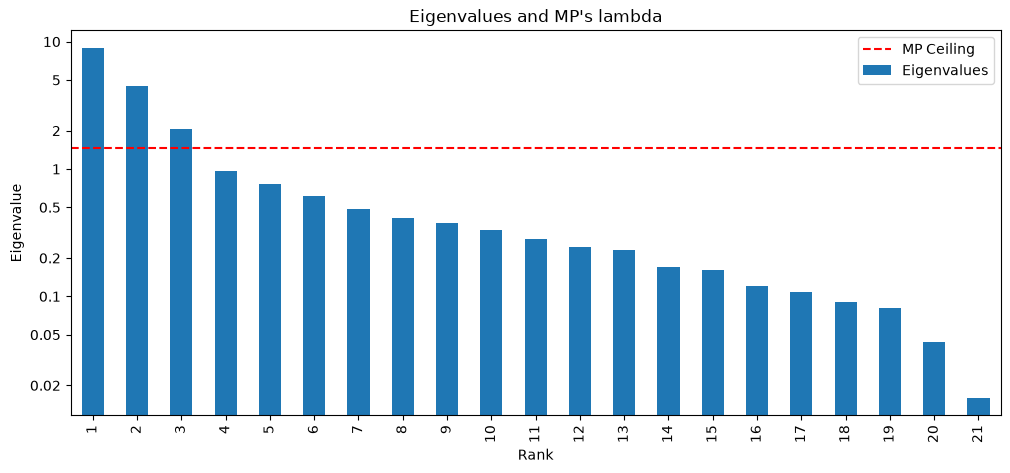

In [251]:
# let's visualize the impact of MP method on eigenvalue filtering

fig, ax = plt.subplots(figsize=(12,5))

eig_series = pd.Series(eigenvals, index=range(1, len(eigenvals) + 1))
eig_series.plot(kind="bar", ax=ax, logy=True, label="Eigenvalues") # log will allow for large differences to not alter the graph too much
ax.axhline(y=mp_upper, color="red", linestyle="--", label="MP Ceiling")
ax.set_title("Eigenvalues and MP's lambda")
ax.set_ylabel("Eigenvalue")
ax.set_xlabel("Rank")
format_log_axis(ax)
ax.legend()

plt.show()


Of the eigenvalues we calculated, the method leaves only 3 as indicative of independent factors

All other vaslues fall below the thresa

In [252]:
# filter noise-led eigenvals out
signal_eigenvals = eigenvals[eigenvals > mp_upper]
print(signal_eigenvals)

[8.93116079 4.49083123 2.0675316 ]


Would be interesting to know which of the factors I mentioned actually made it into the list and which not, or rather if my scaled list was accurate or not

### Denoised Correlation Matrix

Now we will build the new correlation matrix by keeping the 3 eigenvalues above the treshold unchanged, and flatten the remaining 18 to their average

In [253]:
# calculate average of eigenvalues below treshold

noise_eigenvals = eigenvals [eigenvals <=mp_upper]
print(len(noise_eigenvals))

18


In [254]:
# calculate the average
avg_noise_eigenvals = noise_eigenvals.mean()

In [255]:
# replace the noise eigenvalues with their average

eigenvals_denoised = eigenvals.copy()

# here we use a mask because is easier than a for loop
eigenvals_denoised[eigenvals_denoised <= mp_upper] = avg_noise_eigenvals

In [256]:
eigenvals_denoised

array([8.93116079, 4.49083123, 2.0675316 , 0.30613758, 0.30613758,
       0.30613758, 0.30613758, 0.30613758, 0.30613758, 0.30613758,
       0.30613758, 0.30613758, 0.30613758, 0.30613758, 0.30613758,
       0.30613758, 0.30613758, 0.30613758, 0.30613758, 0.30613758,
       0.30613758])

In [257]:
# we now want to reverse engineer the matrix through the new set of denoised eigenvals
# C = V · diag(λ) · Vᵀ

denoised_matrix = eigenvec @ np.diag(eigenvals_denoised) @ eigenvec.T

In [258]:
# rescale so the diagonal is exactly 1 (a proper correlation matrix)
d = np.sqrt(np.diag(denoised_matrix))
denoised_matrix = denoised_matrix / np.outer(d, d)

In [259]:
# back into a DataFrame with the tickers
denoised_corr = pd.DataFrame(denoised_matrix,
                             index=corr_matrix.index,
                             columns=corr_matrix.columns)

In [260]:
# visualize the matrix
denoised_corr.style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1).format("{:.2f}")

Ticker,SPY,QQQ,IWM,EFA,EEM,TLT,IEF,SHY,TIP,LQD,HYG,EMB,EMLC,GLD,DBC,XLE,VNQ,UUP,FXY,FXA,FXF
Ticker,,,,,,,,,,,,,,,,,,,,,
SPY,1.00,0.71,0.73,0.73,0.72,-0.36,-0.36,-0.34,0.02,0.30,0.71,0.60,0.61,0.16,0.64,0.71,0.72,0.01,-0.33,0.46,-0.06
QQQ,0.71,1.00,0.70,0.71,0.69,-0.32,-0.31,-0.30,0.06,0.32,0.68,0.59,0.60,0.17,0.62,0.68,0.69,-0.00,-0.31,0.45,-0.05
IWM,0.73,0.70,1.00,0.73,0.72,-0.34,-0.33,-0.32,0.04,0.31,0.70,0.60,0.63,0.19,0.64,0.70,0.71,-0.03,-0.30,0.48,-0.03
EFA,0.73,0.71,0.73,1.00,0.73,-0.33,-0.32,-0.30,0.05,0.33,0.71,0.60,0.65,0.23,0.65,0.70,0.72,-0.08,-0.25,0.53,0.03
EEM,0.72,0.69,0.72,0.73,1.00,-0.31,-0.30,-0.29,0.06,0.33,0.70,0.60,0.64,0.23,0.64,0.69,0.71,-0.07,-0.25,0.51,0.02
TLT,-0.36,-0.32,-0.34,-0.33,-0.31,1.00,0.72,0.65,0.59,0.40,-0.23,0.08,-0.05,0.23,-0.31,-0.34,-0.31,-0.17,0.40,-0.09,0.22
IEF,-0.36,-0.31,-0.33,-0.32,-0.30,0.72,1.00,0.66,0.59,0.41,-0.22,0.08,-0.02,0.29,-0.30,-0.34,-0.31,-0.24,0.46,-0.04,0.29
SHY,-0.34,-0.30,-0.32,-0.30,-0.29,0.65,0.66,1.00,0.51,0.35,-0.21,0.04,-0.02,0.30,-0.27,-0.33,-0.30,-0.29,0.48,0.01,0.33
TIP,0.02,0.06,0.04,0.05,0.06,0.59,0.59,0.51,1.00,0.61,0.14,0.42,0.28,0.32,0.02,0.02,0.07,-0.14,0.23,0.13,0.18


In [261]:
# calculate eigenvalues and eigenvectors
new_eigenvals = np.linalg.eigh(denoised_corr)[0]
# eigenvals are in ascending order; we need them in descending order
new_eigenvals = np.flip(new_eigenvals)

In [262]:
# compute the condition number

condition_raw = eigenvals.max() / eigenvals.min()
cond_denoised = new_eigenvals.max() / new_eigenvals.min()

In [263]:
print(f"raw: {cond_raw:.0f}, denoised: {cond_denoised:.0f}")
assert cond_denoised < cond_raw

raw: 560, denoised: 33


The condition number practically tells us the most that inverting a matrix can blow up a small estimator error

The denoised condition number tells us that the weights derived with allocators using denoised matrices should be way more stable